Importing required libraries

In [5]:
import mysql.connector
from mysql.connector import Error
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings

Ignore the pandas warnings for cleaner output

In [6]:
# Suppress pandas warnings for cleaner notebook output
warnings.filterwarnings('ignore')

The core OOPS class

In [ ]:
class DSAProblemTracker:
    def __init__(self, host, user, password, database="dsa_tracker_db"):
        """Initialize connection and set up the MySQL database."""
        self.host = host
        self.user = user
        self.password = password
        self.database = database
        self.conn = None
        self.cursor = None
        self._connect_and_setup()

    def _connect_and_setup(self):
        #Creates the database and table structure if they don't exist.
        try:
            temp_conn = mysql.connector.connect(
                host=self.host, 
                user=self.user, 
                password=self.password
            )
            temp_cursor = temp_conn.cursor()
            temp_cursor.execute(f"CREATE DATABASE IF NOT EXISTS {self.database}")
            temp_cursor.close()
            temp_conn.close()

            # Connect to the specific database
            self.conn = mysql.connector.connect(
                host=self.host, user=self.user, password=self.password, database=self.database
            )
            self.cursor = self.conn.cursor()

            # Creating the Database table
            create_table_query = """
            CREATE TABLE IF NOT EXISTS problem_logs (
                id INT AUTO_INCREMENT PRIMARY KEY,
                title VARCHAR(255) NOT NULL,
                difficulty VARCHAR(50) NOT NULL,
                time_taken_mins FLOAT NOT NULL,
                solve_date DATE NOT NULL,
                topic_tags VARCHAR(255) NOT NULL
            )
            """
            self.cursor.execute(create_table_query)
            self.conn.commit()
            print("Database and schema successfully loaded.")
            
        except Error as e:
            print(f"Error connecting to MySQL: {e}")

    def log_problem(self, title, difficulty, time_taken_mins, solve_date, topic_tags):
        #1. Log daily DSA problems into the MySQL database.
        topic_tags = topic_tags.lower()
        query = """
        INSERT INTO problem_logs (title, difficulty, time_taken_mins, solve_date, topic_tags)
        VALUES (%s, %s, %s, %s, %s)
        """
        values = (title, difficulty, time_taken_mins, solve_date, topic_tags)
        
        try:
            self.cursor.execute(query, values)
            self.conn.commit()
        except Error as e:
            print(f"Error logging problem: {e}")

    def get_dataframe(self):
        #Fetch all data from MySQL into a Pandas DataFrame
        query = "SELECT * FROM problem_logs"
        df = pd.read_sql(query, self.conn)
        df['solve_date'] = pd.to_datetime(df['solve_date'])
        return df

    def calculate_streak(self):
        #2. Calculate and display the user's consecutive daily streak
        df = self.get_dataframe()
        if df.empty:
            return 0
            
        # Get unique dates sorted in descending order
        unique_dates = df['solve_date'].dt.date.drop_duplicates().sort_values(ascending=False).tolist()
        
        if not unique_dates:
            return 0

        streak = 1
        current_date = unique_dates[0]

        for i in range(1, len(unique_dates)):
            expected_date = current_date - timedelta(days=1)
            if unique_dates[i] == expected_date:
                streak += 1
                current_date = unique_dates[i]
            else:
                break
                
        print(f"Current Active Streak: {streak} Day(s)!")
        return streak

    def identify_weak_topics(self):
        #3. Use Pandas to identify weakest topics based on average time taken
        df = self.get_dataframe()
        if df.empty:
            print("No data available.")
            return
            
        # Handle comma-separated tags for topic-level aggregation
        df['topic'] = df['topic_tags'].str.split(',')
        df_exploded = df.explode('topic')
        df_exploded['topic'] = df_exploded['topic'].str.strip() # Clean whitespace

        # Calculate average time per topic
        weak_topics = df_exploded.groupby('topic')['time_taken_mins'].mean().reset_index()
        weak_topics = weak_topics.sort_values(by='time_taken_mins', ascending=False)

        print("\nWeakest Topics (Highest Avg Execution Time):")
        print(weak_topics.head().to_string(index=False))
        return weak_topics

    def generate_dashboards(self):
        #4. Generate Matplotlib visual dashboards
        df = self.get_dataframe()
        if df.empty:
            print("Not enough data to generate dashboards.")
            return

        fig = plt.figure(figsize=(18, 5))

        #Subplot 1: Bar Chart (Topic Distribution)
        df_exploded = df.assign(topic=df['topic_tags'].str.split(',')).explode('topic')
        df_exploded['topic'] = df_exploded['topic'].str.strip()
        topic_counts = df_exploded['topic'].value_counts()

        ax1 = fig.add_subplot(131)
        topic_counts.plot(kind='bar', color='skyblue', ax=ax1)
        ax1.set_title('Problems Solved per Topic', fontweight='bold')
        ax1.set_ylabel('Number of Problems')
        ax1.tick_params(axis='x', rotation=45)

        #Subplot 2: Pie Chart (Difficulty Consistency)
        difficulty_counts = df['difficulty'].value_counts()
        colors = ['#ff9999','#66b3ff','#99ff99']
        
        ax2 = fig.add_subplot(132)
        difficulty_counts.plot(kind='pie', autopct='%1.1f%%', colors=colors, startangle=90, ax=ax2)
        ax2.set_title('Difficulty Distribution', fontweight='bold')
        ax2.set_ylabel('') 

        #Subplot 3: Line Chart (Time Trends over Semester)
        time_trend = df.groupby('solve_date')['time_taken_mins'].mean()
        
        ax3 = fig.add_subplot(133)
        time_trend.plot(kind='line', marker='o', color='purple', linewidth=2, ax=ax3)
        ax3.set_title('Avg Execution Time Trend', fontweight='bold')
        ax3.set_xlabel('Date')
        ax3.set_ylabel('Avg Time (mins)')
        ax3.grid(True, linestyle='--', alpha=0.6)
        ax3.tick_params(axis='x', rotation=45)

        plt.tight_layout()
        plt.show()

    def close_connection(self):
        """Cleanly close the database connection."""
        if self.cursor:
            self.cursor.close()
        if self.conn:
            self.conn.close()
        print("Database connection closed.")

Giving sample data for trying

In [8]:
# Initialize the tracker (Ensure your local MySQL server is running)
tracker = DSAProblemTracker(host="127.0.0.1", user="root", password="Nikhil1245780$")

# Simulate User Logging Data 
sample_data = [
    ("Two Sum", "Easy", 15.5, "2023-10-01", "Arrays, Hash Table"),
    ("Reverse Linked List", "Easy", 12.0, "2023-10-02", "Linked List"),
    ("Longest Substring", "Medium", 45.0, "2023-10-03", "Strings, Sliding Window"),
    ("Merge K Sorted Lists", "Hard", 85.5, "2023-10-04", "Linked List, Divide and Conquer, Heap"),
    ("Valid Parentheses", "Easy", 10.0, "2023-10-05", "Stack, Strings"),
    ("Minimum Window Substring", "Hard", 95.0, "2023-10-06", "Strings, Sliding Window"),
    ("Climbing Stairs", "Easy", 8.0, "2023-10-07", "Dynamic Programming"),
    ("Coin Change", "Medium", 55.0, "2023-10-08", "Dynamic Programming, Arrays")
]

# Insert sample logs into MySQL
for problem in sample_data:
    tracker.log_problem(*problem)
    
print("Sample problems dynamically logged into MySQL.")

Database and schema successfully loaded.
Sample problems dynamically logged into MySQL.


Further Enter data (User enter during runtime)

In [ ]:
while True:
    print("Enter 1 for entering the details and Enter 2 to exit.")
    choice = input("Enter your choice(1/2): ")
    flag = True
    if choice == '1':
        question = input("Enter the title of question: ")
        difficulty = input("Enter difficulty(E/M/H): ")
        if difficulty.lower()=='e':
            difficulty = "Easy"
        elif difficulty.lower()=='m':
            difficulty = "Medium"
        elif difficulty.lower()=='h':
            difficulty = "Hard"
        else:
            print("Enter valid difficulty, select in E/M/H.")
            flag = False
            continue

        try:
            time_taken = float(input("Enter time taken in minutes: "))
        except ValueError:
            print("Invalid time! Please enter a numerical value.")
            flag = False
            continue

        print("Select from option(1, 2): ")
        print("1. Select custom date(Entered by user)")
        print("2. Select the current date")
        choice1 = input("Enter your choice: ")
        if choice1 == '1':
            date_sol = input("Enter a date (DD/MM/YYYY): ")
            try:
                # 2. Parse the string matching the user's expected input format
                parsed_date = datetime.strptime(date_sol, "%d/%m/%Y")
                
                # 3. Format the date object into YYYY-MM-DD
                formatted_date = parsed_date.strftime("%Y-%m-%d")
                
                date_sol = formatted_date

            except ValueError:
                print("Invalid date format! Please use DD/MM/YYYY.")
                flag = False
        elif choice1 == '2':
            # Get the current local date and convert to YYYY-MM-DD string
            date_sol = datetime.today().strftime("%Y-%m-%d")
        else:
            print("Enter valid choice, select in 1/2.")
            flag = False

        topics = input("Enter all the topics involved (separated by commas, e.g. Arrays, Linked List): ")

        if flag == True:
            curr_data = (question, difficulty, time_taken, date_sol, topics)
            tracker.log_problem(*curr_data)
        else:
            print("You entered data wrong somewhere. Enter data based on given conditions.")

    elif choice == '2':
        print("Exiting logger...")
        break
    else:
        print("Enter a valid choice(select between 1 and 2)")
    

Viewing the dashboard

Current Active Streak: 8 Day(s)!

Weakest Topics (Highest Avg Execution Time):
             topic  time_taken_mins
Divide and Conquer            85.50
              Heap            85.50
    Sliding Window            70.00
           Strings            50.00
       Linked List            48.75


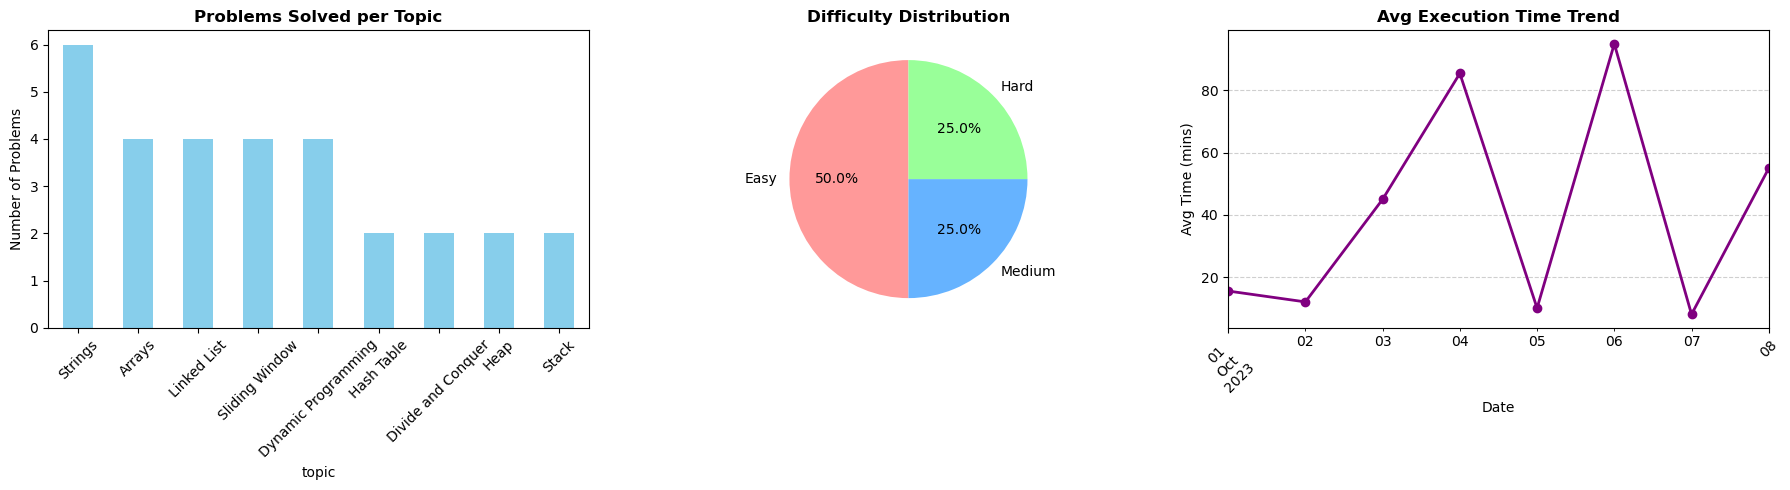

In [9]:
# 1. Calculate daily streak
tracker.calculate_streak()

# 2. Identify Weak Topics via Pandas Time-Series
tracker.identify_weak_topics()

# 3. Generate Matplotlib Dashboards
tracker.generate_dashboards()

In [ ]:
# Close the MySQL connection safely
tracker.close_connection()